# Классификация аудио

Сравниваем три представления аудиосигнала: MFCC, признаки предобученного `wav2vec2-base` и признаки после дообучения модели на целевой задаче.

В терминах задачи мы строим отображение

$$
f: x \rightarrow y, \quad y \in \{1,\dots,C\}
$$

где $x$ — аудиозапись, а $y$ — метка класса.

1. Загрузим и подготовим данные.
2. Вытащим MFCC-признаки и агрегируем.
3. Визуализируем и сравненим классические модели.
4. Проверим признаки предобученной глубокой модели.
5. Обучим классификационую голову.
6. Fine-tuning всей сети.
7. Выберем лучшее пространства и посмотрим близкие/дальние пары через спектрограммы.

In [19]:
import io
import os
import random
import textwrap
import warnings
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
import torch
import torch.nn as nn
from IPython.display import display
from scipy.spatial.distance import pdist
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
from transformers import AutoFeatureExtractor, AutoModel

try:
    import umap
    HAS_UMAP = True
except Exception:
    HAS_UMAP = False

# **1-2**. Подготовка 

На практике parquet-файлы (которые даты для анализа Биг даты) могут хранить аудио по-разному: как массив, путь к файлу, байты или словарь с метаданными. Поэтому сначала всё приводится к единому формату записи, чтобы дальше один и тот же код работал для любых этапов эксперимента.

Каждый объект после нормализации имеет вид

$$
s_i = (\mathbf{w}_i, \; disr_i, \; y_i, \; id_i)
$$

где $\mathbf{w}_i$ — форма волны аудио, $discr_i$ — частота дискретизации, $y_i$ — класс, $id_i$ — идентификатор.

Пихаем выборки как $D_{train}$ и $D_{test}$, и весь пайплайн работает уже с ними без дополнительных преобразований формата.

In [20]:
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

sns.set_theme(style='darkgrid', context='talk', palette='deep')
plt.rcParams.update({
    'figure.dpi': 125,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'figure.facecolor': '#11151c',
    'axes.facecolor': '#1b2230',
    'axes.edgecolor': '#d7deea',
    'axes.labelcolor': '#e9edf5',
    'text.color': '#f2f4f8',
    'xtick.color': '#d0d8e4',
    'ytick.color': '#d0d8e4',
    'grid.color': '#3b4658',
    'grid.alpha': 0.45,
    'legend.facecolor': '#202838',
    'legend.edgecolor': '#5a6880',
    'savefig.facecolor': '#11151c',
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

DATA_DIR = Path('.')
TRAIN_FILE = DATA_DIR / 'train-00000-of-00001.parquet'
TEST_FILE = DATA_DIR / 'test-00000-of-00001.parquet'

TARGET_SR_MFCC = 16000
N_MFCC = 20
HOP_LENGTH = 320
N_FFT = 1024

BACKBONE_NAME = 'facebook/wav2vec2-base'
BACKBONE_SR = 16000

MAX_TRAIN_SAMPLES = None
MAX_TEST_SAMPLES = None


def _pick_label_column(df: pd.DataFrame) -> str:
    priority = ['label', 'labels', 'target', 'class', 'category', 'y', 'nombreCientifico']
    for col in priority:
        if col in df.columns:
            return col

    ignore_tokens = ['path', 'file', 'archivo', 'name', 'id', 'audio']
    n_rows = len(df)
    candidates = []

    for col in df.columns:
        col_lower = col.lower()
        if any(token in col_lower for token in ignore_tokens):
            continue
        if col == 'audio':
            continue
        nunique = df[col].nunique(dropna=False)
        if nunique <= 1:
            continue
        if nunique >= 0.8 * n_rows:
            continue
        candidates.append((col, nunique, str(df[col].dtype)))

    if candidates:
        obj_candidates = [item for item in candidates if item[2] in ('object', 'string')]
        if obj_candidates:
            obj_candidates.sort(key=lambda x: x[1])
            return obj_candidates[0][0]
        candidates.sort(key=lambda x: x[1])
        return candidates[0][0]

    return min(df.columns, key=lambda c: df[c].nunique(dropna=False))


def _pick_audio_column(df: pd.DataFrame, label_col: str) -> str:
    if 'audio' in df.columns:
        return 'audio'

    for col in df.columns:
        if col == label_col:
            continue
        sample = df[col].dropna().iloc[0] if df[col].notna().any() else None
        if isinstance(sample, (dict, list, np.ndarray, bytes, str)):
            return col

    raise ValueError('Не удалось определить колонку с аудио.')


def _load_audio_from_entry(entry, base_dir: Path):
    if isinstance(entry, dict):
        if entry.get('array') is not None:
            y = np.asarray(entry['array'], dtype=np.float32)
            sr = int(entry.get('sampling_rate') or TARGET_SR_MFCC)
        elif entry.get('bytes') is not None:
            with io.BytesIO(entry['bytes']) as bio:
                y, sr = sf.read(bio, dtype='float32', always_2d=False)
        elif entry.get('path') is not None:
            path = Path(entry['path'])
            if not path.is_absolute():
                path = base_dir / path
            y, sr = librosa.load(path, sr=None, mono=True)
        else:
            raise ValueError('Неизвестный формат словаря audio.')
    elif isinstance(entry, (list, np.ndarray)):
        y = np.asarray(entry, dtype=np.float32)
        sr = TARGET_SR_MFCC
    elif isinstance(entry, (str, os.PathLike, Path)):
        path = Path(entry)
        if not path.is_absolute():
            path = base_dir / path
        y, sr = librosa.load(path, sr=None, mono=True)
    elif isinstance(entry, (bytes, bytearray)):
        with io.BytesIO(entry) as bio:
            y, sr = sf.read(bio, dtype='float32', always_2d=False)
    else:
        raise ValueError(f'Неподдерживаемый формат аудио: {type(entry)}')

    y = np.asarray(y, dtype=np.float32)
    if y.ndim > 1:
        y = np.mean(y, axis=1)
    return y, int(sr)


def _pick_id_value(row, idx):
    for key in ['sample_id', 'path', 'archivo', 'file', 'filename', 'id']:
        if key in row and pd.notna(row[key]):
            return str(row[key])
    return str(idx)


def load_split(parquet_path: Path, max_samples=None):
    df = pd.read_parquet(parquet_path)
    if max_samples is not None:
        df = df.iloc[:max_samples].copy()

    label_col = _pick_label_column(df)
    audio_col = _pick_audio_column(df, label_col)

    waves, srs, labels, ids = [], [], [], []
    skipped_rows = 0
    base_dir = parquet_path.parent

    for idx, row in tqdm(df.iterrows(), total=len(df), desc=f'Loading {parquet_path.name}'):
        try:
            y, sr = _load_audio_from_entry(row[audio_col], base_dir)
            waves.append(y)
            srs.append(sr)
            labels.append(row[label_col])
            ids.append(_pick_id_value(row, idx))
        except Exception:
            skipped_rows += 1

    out_df = pd.DataFrame({
        'sample_id': ids,
        'label': labels,
        'waveform': waves,
        'sr': srs,
    })
    meta = {
        'label_col': label_col,
        'audio_col': audio_col,
        'source_rows': len(df),
        'loaded_rows': len(out_df),
        'skipped_rows': skipped_rows,
    }
    return out_df, meta

Device: cuda



Кодируем метки в целые индексы, посмотрим распределение классов отдельно для train. Отследим дисбаланс.

Доля класса $c$ в выборке считается как

$$
p_c = \frac{n_c}{N}
$$

где $n_c$ — число объектов класса, $N$ — общий размер выборки.

Для сравнения моделей дальше возьмём macro-F1:

$$
F1_{macro} = \frac{1}{C}\sum_{c=1}^{C} F1_c
$$

Поможет при перекосе частот и установит одинаковые веса классам.

Loading test-00000-of-00001.parquet: 100%|██████████| 80/80 [00:00<00:00, 2889.41it/s]


Train meta: {'label_col': 'nombreCientifico', 'audio_col': 'audio', 'source_rows': 320, 'loaded_rows': 320, 'skipped_rows': 0}
Test meta: {'label_col': 'nombreCientifico', 'audio_col': 'audio', 'source_rows': 80, 'loaded_rows': 80, 'skipped_rows': 0}
Train size: 320 Test size: 80
Classes: ['Accipiter striatus', 'Acropternis orthonyx']


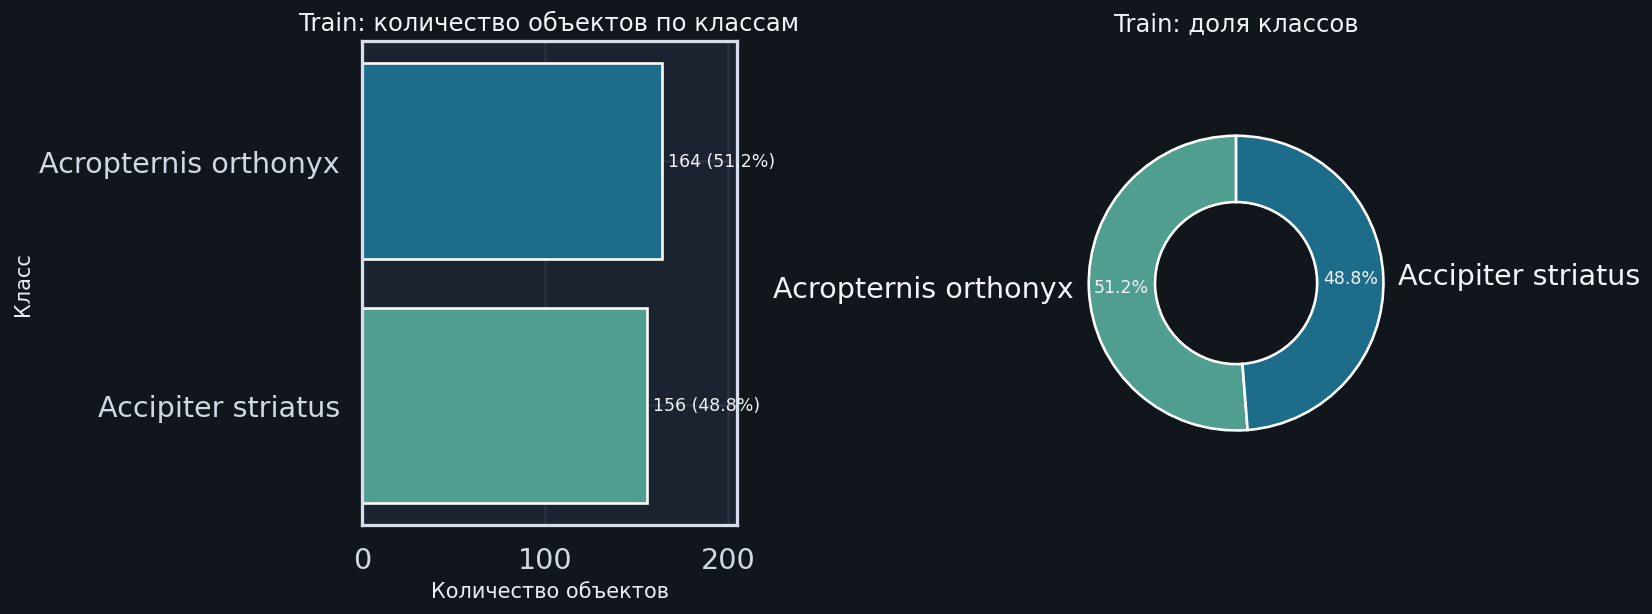

,class,count,share_%
0,Acropternis orthonyx,164,51.25
1,Accipiter striatus,156,48.75


Классов в train: 2. Самый частый класс: Acropternis orthonyx (51.25%).
Соотношение между классами: 164 к 156 (x1.05).


In [21]:
train_df, train_meta = load_split(TRAIN_FILE, max_samples=MAX_TRAIN_SAMPLES)
test_df, test_meta = load_split(TEST_FILE, max_samples=MAX_TEST_SAMPLES)

print('Train meta:', train_meta)
print('Test meta:', test_meta)
print('Train size:', len(train_df), 'Test size:', len(test_df))

label_encoder = LabelEncoder()
label_encoder.fit(pd.concat([train_df['label'], test_df['label']], axis=0))
y_train = label_encoder.transform(train_df['label'])
y_test = label_encoder.transform(test_df['label'])
class_names = list(label_encoder.classes_)
print('Classes:', class_names)

class_counts = train_df['label'].value_counts(dropna=False).sort_values(ascending=False)
class_share = class_counts / class_counts.sum() * 100
n_classes = int(class_counts.shape[0])


def format_count(x):
    return f'{int(x):,}'.replace(',', ' ')


if n_classes == 2:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
    ordered = class_counts.sort_values(ascending=True)
    colors = sns.color_palette('crest', n_colors=2)

    bars = axes[0].barh(ordered.index.astype(str), ordered.values, color=colors)
    axes[0].set_title('Train: количество объектов по классам')
    axes[0].set_xlabel('Количество объектов')
    axes[0].set_ylabel('Класс')

    max_val = float(ordered.max())
    axes[0].set_xlim(0, max_val * 1.25 if max_val > 0 else 1)

    for bar, label in zip(bars, ordered.index):
        count = int(ordered.loc[label])
        pct = float(class_share.loc[label])
        axes[0].text(
            bar.get_width() + max_val * 0.02,
            bar.get_y() + bar.get_height() / 2,
            f'{format_count(count)} ({pct:.1f}%)',
            va='center',
            ha='left',
            fontsize=10,
        )

    wedges, _, autotexts = axes[1].pie(
        class_counts.values,
        labels=class_counts.index.astype(str),
        autopct=lambda p: f'{p:.1f}%',
        startangle=90,
        pctdistance=0.78,
        colors=colors,
        wedgeprops={'width': 0.45, 'edgecolor': 'white'},
    )
    for t in autotexts:
        t.set_color('#f2f4f8')
        t.set_fontsize(10)

    axes[1].set_title('Train: доля классов')
    axes[1].axis('equal')
else:
    if n_classes <= 12:
        fig, ax = plt.subplots(figsize=(max(10, 0.8 * n_classes + 6), 5.4), constrained_layout=True)
        labels = class_counts.index.astype(str)
        bars = ax.bar(labels, class_counts.values, color=sns.color_palette('viridis', n_colors=n_classes))
        ax.set_title(f'Распределение классов в train (классов: {n_classes})')
        ax.set_xlabel('Класс')
        ax.set_ylabel('Количество объектов')
        ax.tick_params(axis='x', rotation=35)

        ymax = float(class_counts.max())
        ax.set_ylim(0, ymax * 1.2 if ymax > 0 else 1)

        for bar, label in zip(bars, class_counts.index):
            count = int(class_counts.loc[label])
            pct = float(class_share.loc[label])
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + ymax * 0.02,
                f'{format_count(count)}\n({pct:.1f}%)',
                ha='center',
                va='bottom',
                fontsize=9,
            )
    else:
        top_k = 12
        top_counts = class_counts.head(top_k).copy()
        other_count = int(class_counts.iloc[top_k:].sum())
        top_display = top_counts.copy()
        if other_count > 0:
            top_display.loc['Остальные'] = other_count

        top_share = top_display / class_counts.sum() * 100

        fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
        labels = top_display.index.astype(str)
        bars = ax.bar(labels, top_display.values, color=sns.color_palette('viridis', n_colors=len(top_display)))
        ax.set_title(f'Распределение классов в train (топ-{top_k} + остальные)')
        ax.set_xlabel('Класс')
        ax.set_ylabel('Количество объектов')
        ax.tick_params(axis='x', rotation=40)

        ymax = float(top_display.max())
        ax.set_ylim(0, ymax * 1.25 if ymax > 0 else 1)

        for bar, label in zip(bars, top_display.index):
            count = int(top_display.loc[label])
            pct = float(top_share.loc[label])
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + ymax * 0.02,
                f'{format_count(count)}\n({pct:.1f}%)',
                ha='center',
                va='bottom',
                fontsize=9,
            )

        print(f'Показаны топ-{top_k} классов, остальные объединены в категорию "Остальные".')

plt.show()

class_stats = pd.DataFrame({
    'class': class_counts.index.astype(str),
    'count': class_counts.values,
    'share_%': class_share.values,
})
class_stats['share_%'] = class_stats['share_%'].round(2)
display(class_stats)

dominant_class = class_counts.index[0]
rare_class = class_counts.index[-1]
imbalance_ratio = class_counts.iloc[0] / class_counts.iloc[-1] if class_counts.iloc[-1] > 0 else float('inf')

print(f'Классов в train: {n_classes}. Самый частый класс: {dominant_class} ({class_share.iloc[0]:.2f}%).')
if n_classes == 2:
    print(f'Соотношение между классами: {class_counts.iloc[0]} к {class_counts.iloc[1]} (x{imbalance_ratio:.2f}).')
else:
    print(f'Разброс между самым частым и самым редким классом: x{imbalance_ratio:.2f}.')

# **3**. MFCC-признаки

MFCC (Mel-Frequency Cepstral Coefficients, Мел-частотные кепстральные коэффициенты) — компактное описание спектральной формы сигнала в шкале, приближенной к слуховому восприятию.
Для каждого аудио получается матрица признаков

$$
\mathbf{M}_i \in \mathbb{R}^{K \times T_i}
$$

где $K$ — число коэффициентов, $T_i$ — число временных кадров. Чтобы подать это в классические модели, агрегируем в фиксированный вектор статистик:

$$
\phi(\mathbf{M}_i) = [\mu(\mathbf{M}_i),\ \sigma(\mathbf{M}_i),\ \min(\mathbf{M}_i),\ \max(\mathbf{M}_i)]
$$

In [22]:
def resample_if_needed(y, sr, target_sr):
    if sr == target_sr:
        return y
    return librosa.resample(y, orig_sr=sr, target_sr=target_sr)


def aggregate_sequence_features(seq_2d: np.ndarray):
    if seq_2d.ndim != 2:
        raise ValueError('Ожидался 2D-массив [features, time] или [time, features].')

    if seq_2d.shape[0] > seq_2d.shape[1]:
        seq_2d = seq_2d.T

    mean = seq_2d.mean(axis=1)
    std = seq_2d.std(axis=1)
    minv = seq_2d.min(axis=1)
    maxv = seq_2d.max(axis=1)
    return np.concatenate([mean, std, minv, maxv], axis=0)


def extract_mfcc_features(df: pd.DataFrame, target_sr=TARGET_SR_MFCC, n_mfcc=N_MFCC):
    features = []
    for y, sr in tqdm(zip(df['waveform'], df['sr']), total=len(df), desc='MFCC extraction'):
        y_rs = resample_if_needed(y, sr, target_sr)
        mfcc = librosa.feature.mfcc(
            y=y_rs,
            sr=target_sr,
            n_mfcc=n_mfcc,
            n_fft=N_FFT,
            hop_length=HOP_LENGTH,
        )
        features.append(aggregate_sequence_features(mfcc))
    return np.asarray(features, dtype=np.float32)


X_train_mfcc = extract_mfcc_features(train_df)
X_test_mfcc = extract_mfcc_features(test_df)

print('MFCC feature shape train:', X_train_mfcc.shape)
print('MFCC feature shape test:', X_test_mfcc.shape)

MFCC extraction: 100%|██████████| 80/80 [00:00<00:00, 312.05it/s]

MFCC feature shape train: (320, 80)
MFCC feature shape test: (80, 80)


# **4**. Визуализация признакового пространства и классические модели

Высокоразмерные признаки сначала стандартизируются, затем сжимаются PCA, после чего проецируются в 2D через UMAP (или TSNE, оба имба, но UMAP имбовее так как это многообразия, а многообразия это продвинутая математика). 

Стандартизация по признакам:

$$
\tilde{x}_j = \frac{x_j - \mu_j}{\sigma_j}
$$

Проекция PCA:

$$
\mathbf{z} = W^\top \tilde{\mathbf{x}}
$$

После визуализации на этих же признаках сравниваем `LogReg`, `SVM-RBF` и `RandomForest`, чтобы чекнуть, насколько пространство уже разделяет классы без глубокого end-to-end обучения.

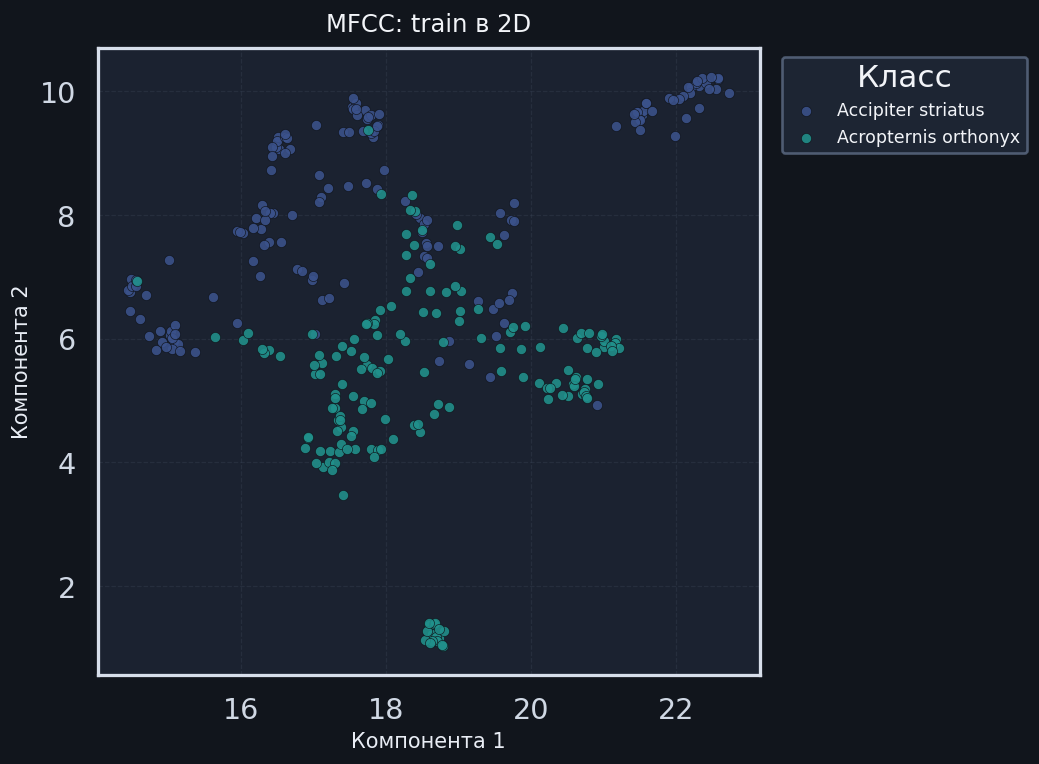

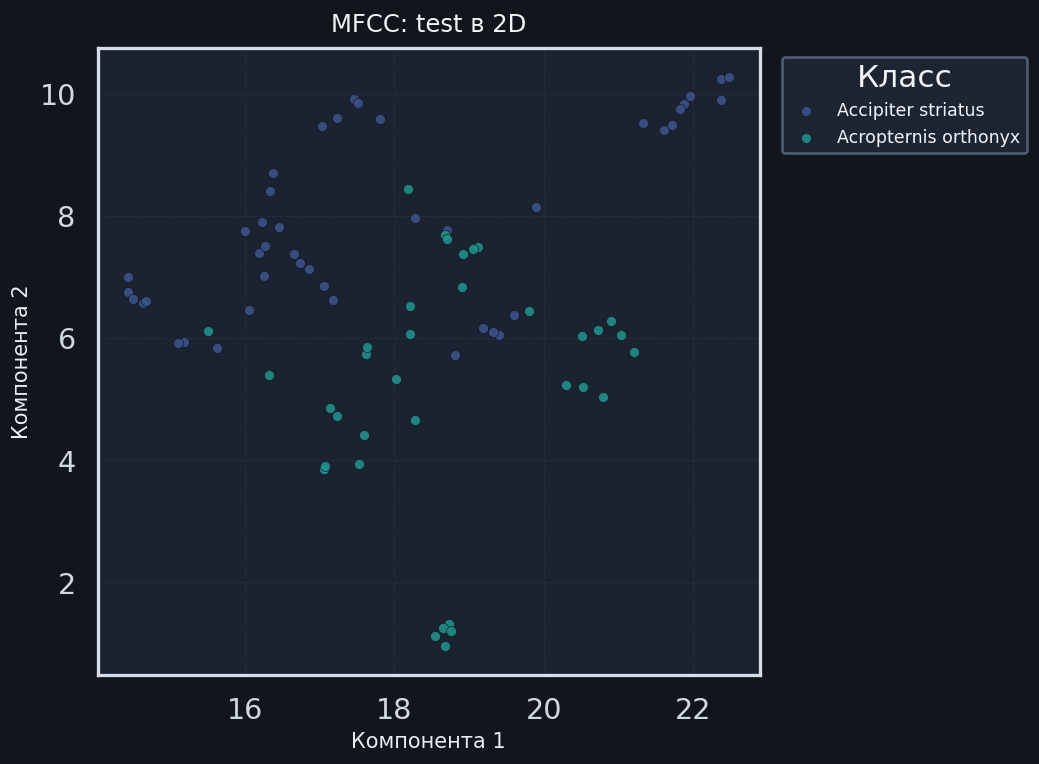

MFCC classical models:


,model,accuracy,f1_macro
0,SVM-RBF,0.9750,0.974603
1,RandomForest,0.9625,0.961777
2,LogReg,0.9500,0.949206


Лучший алгоритм SVM-RBF.
Качество: accuracy=0.9750, f1_macro=0.9746.


In [23]:
def reduce_to_2d(X_train, X_test, method='umap', random_state=SEED):
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc = scaler.transform(X_test)

    pca = PCA(n_components=min(50, X_train_sc.shape[1]), random_state=random_state)
    X_train_pca = pca.fit_transform(X_train_sc)
    X_test_pca = pca.transform(X_test_sc)

    X_all = np.vstack([X_train_pca, X_test_pca])

    if method == 'umap' and HAS_UMAP:
        reducer = umap.UMAP(n_components=2, random_state=random_state)
    else:
        perplexity = min(30, max(2, len(X_all) - 1))
        reducer = TSNE(
            n_components=2,
            random_state=random_state,
            init='pca',
            learning_rate='auto',
            perplexity=perplexity,
        )

    X_all_2d = reducer.fit_transform(X_all)
    return X_all_2d[:len(X_train)], X_all_2d[len(X_train):]


def plot_2d_space(X2d, y, labels, title):
    fig, ax = plt.subplots(figsize=(8.2, 6), constrained_layout=True)
    unique_classes = np.unique(y)
    palette = sns.color_palette('viridis', n_colors=max(3, len(unique_classes)))

    for cls, color in zip(unique_classes, palette):
        mask = y == cls
        ax.scatter(
            X2d[mask, 0],
            X2d[mask, 1],
            s=34,
            alpha=0.88,
            color=color,
            edgecolors='#0f1218',
            linewidths=0.4,
            label=str(labels[cls]),
        )

    ax.set_title(title, pad=10)
    ax.set_xlabel('Компонента 1')
    ax.set_ylabel('Компонента 2')
    ax.grid(alpha=0.35, linestyle='--', linewidth=0.7)
    legend = ax.legend(title='Класс', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
    if legend is not None:
        legend.get_frame().set_alpha(0.85)
    plt.show()


def evaluate_classic_models(X_train, y_train, X_test, y_test):
    try:
        from sklearn.svm import SVC as SVCModel
    except Exception as exc:
        raise RuntimeError('Не удалось импортировать sklearn.svm.SVC') from exc
    models = {
        'LogReg': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', LogisticRegression(max_iter=3000, random_state=SEED)),
        ]),
        'SVM-RBF': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', SVCModel(kernel='rbf', probability=True, random_state=SEED)),
        ]),
        'RandomForest': RandomForestClassifier(
            n_estimators=400,
            random_state=SEED,
            n_jobs=-1,
            class_weight='balanced',
        ),
    }

    rows = []
    fitted = {}
    for name, model in models.items():
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        rows.append({
            'model': name,
            'accuracy': accuracy_score(y_test, pred),
            'f1_macro': f1_score(y_test, pred, average='macro'),
        })
        fitted[name] = model

    metrics_df = pd.DataFrame(rows).sort_values('f1_macro', ascending=False).reset_index(drop=True)
    return metrics_df, fitted


def print_space_summary(space_name, metrics_df):
    best_row = metrics_df.iloc[0]
    print(f'Лучший алгоритм {best_row["model"]}.')
    print(
        f'Качество: accuracy={best_row["accuracy"]:.4f}, '
        f'f1_macro={best_row["f1_macro"]:.4f}.'
    )


Xtr2_mfcc, Xte2_mfcc = reduce_to_2d(X_train_mfcc, X_test_mfcc, method='umap')
plot_2d_space(Xtr2_mfcc, y_train, class_names, 'MFCC: train в 2D')
plot_2d_space(Xte2_mfcc, y_test, class_names, 'MFCC: test в 2D')

mfcc_metrics, mfcc_models = evaluate_classic_models(X_train_mfcc, y_train, X_test_mfcc, y_test)
print('MFCC classical models:')
display(mfcc_metrics)
print_space_summary('MFCC-пространства', mfcc_metrics)

# **5**. Предобученная модель для извлечения признаков

`facebook/wav2vec2-base` работает с сырым аудио и ожидает частоту 16 кГц. На выходе модель даёт последовательность скрытых состояний

$$
\mathbf{H}_i \in \mathbb{R}^{T_i \times D}
$$

где $T_i$ — длина последовательности по времени, $D$ — размер скрытого пространства.

Чтобы сравнивать это пространство с MFCC в одинаковых условиях, каждую последовательность снова сводим к фиксированному вектору статистик. После этого выполняем схему выше.

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Backbone loaded: facebook/wav2vec2-base
Expected sampling rate: 16000


Backbone features test: 100%|██████████| 10/10 [00:01<00:00,  8.01it/s]


Pretrained feature shape train: (320, 3072)
Pretrained feature shape test: (80, 3072)


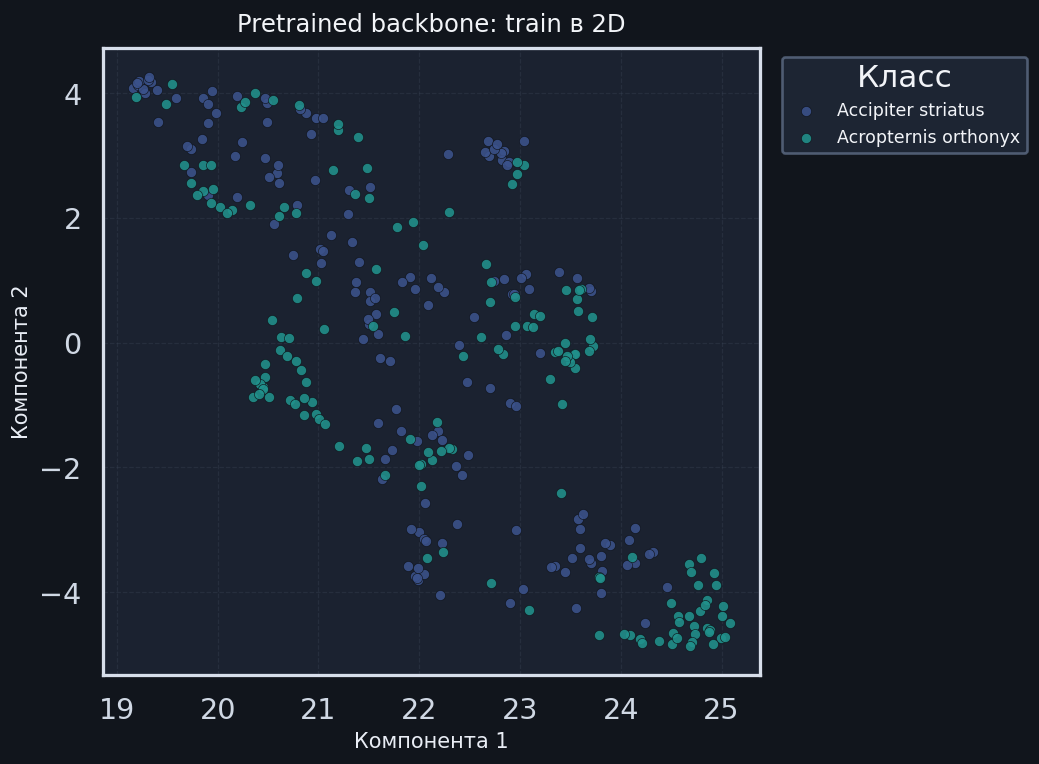

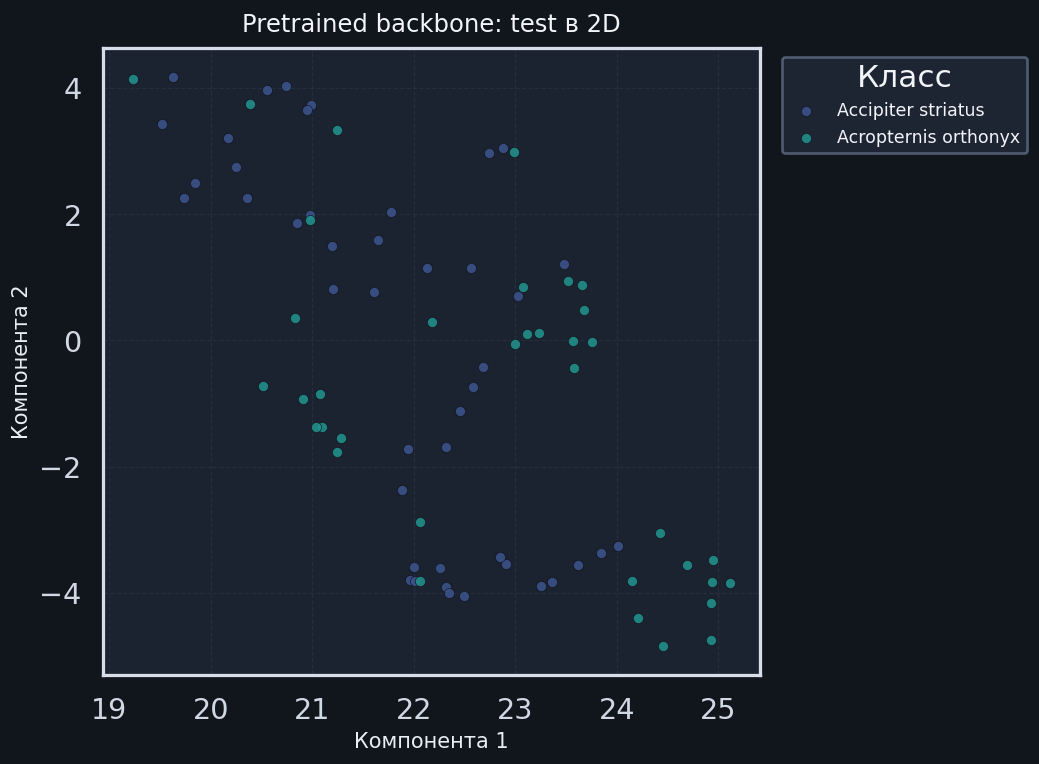

Pretrained-feature classical models:


,model,accuracy,f1_macro
0,LogReg,0.9500,0.949206
1,SVM-RBF,0.9125,0.910127
2,RandomForest,0.9000,0.897698


Лучший алгоритм LogReg.
Качество: accuracy=0.9500, f1_macro=0.9492.


In [24]:
for proxy_key in ['http_proxy', 'https_proxy', 'HTTP_PROXY', 'HTTPS_PROXY', 'all_proxy', 'ALL_PROXY']:
    os.environ.pop(proxy_key, None)

feature_extractor = AutoFeatureExtractor.from_pretrained(BACKBONE_NAME)
backbone = AutoModel.from_pretrained(BACKBONE_NAME).to(device)
backbone.eval()

print('Backbone loaded:', BACKBONE_NAME)
print('Expected sampling rate:', feature_extractor.sampling_rate)


def to_backbone_sr(y, sr, target_sr=BACKBONE_SR):
    if sr == target_sr:
        return y.astype(np.float32)
    return librosa.resample(y.astype(np.float32), orig_sr=sr, target_sr=target_sr)


train_wavs_16k = [to_backbone_sr(y, sr) for y, sr in tqdm(zip(train_df['waveform'], train_df['sr']), total=len(train_df), desc='Resample train')]
test_wavs_16k = [to_backbone_sr(y, sr) for y, sr in tqdm(zip(test_df['waveform'], test_df['sr']), total=len(test_df), desc='Resample test')]


@torch.inference_mode()
def extract_backbone_vectors(wave_list, batch_desc='Extracting backbone features', batch_size=8):
    vectors = []
    sequences = []

    for start in tqdm(range(0, len(wave_list), batch_size), desc=batch_desc):
        batch = wave_list[start:start + batch_size]
        encoded = feature_extractor(
            batch,
            sampling_rate=BACKBONE_SR,
            return_tensors='pt',
            padding=True,
        )
        encoded = {k: v.to(device) for k, v in encoded.items()}
        last_hidden = backbone(**encoded).last_hidden_state.detach().cpu().numpy()

        if 'attention_mask' in encoded:
            lengths = encoded['attention_mask'].detach().cpu().numpy().sum(axis=1).astype(int)
        else:
            lengths = np.full(len(batch), last_hidden.shape[1], dtype=int)

        for i, length in enumerate(lengths):
            valid_len = max(1, int(length))
            seq = last_hidden[i, :valid_len]
            sequences.append(seq)
            vectors.append(np.concatenate([
                seq.mean(axis=0),
                seq.std(axis=0),
                seq.min(axis=0),
                seq.max(axis=0),
            ], axis=0))

    return np.asarray(vectors, dtype=np.float32), sequences


X_train_pre, train_seq_pre = extract_backbone_vectors(train_wavs_16k, 'Backbone features train')
X_test_pre, test_seq_pre = extract_backbone_vectors(test_wavs_16k, 'Backbone features test')

print('Pretrained feature shape train:', X_train_pre.shape)
print('Pretrained feature shape test:', X_test_pre.shape)

Xtr2_pre, Xte2_pre = reduce_to_2d(X_train_pre, X_test_pre, method='umap')
plot_2d_space(Xtr2_pre, y_train, class_names, 'Pretrained backbone: train в 2D')
plot_2d_space(Xte2_pre, y_test, class_names, 'Pretrained backbone: test в 2D')

pre_metrics, pre_models = evaluate_classic_models(X_train_pre, y_train, X_test_pre, y_test)
print('Pretrained-feature classical models:')
display(pre_metrics)
print_space_summary('предобученного признакового пространства', pre_metrics)

# **6**. Обучение классификационной head

На этом шаге backbone оставляем замороженным и обучаем только классификационную голову. Это даёт быстрый baseline: насколько хорошо решается задача, если extractor уже предобучен и не адаптируется к текущему датасету.

Оптимизируем кросс-энтропию

$$
\mathcal{L}_{CE} = -\frac{1}{N}\sum_{i=1}^{N}\log p_\theta(y_i\mid x_i)
$$

По эпохам отслеживаются loss, accuracy и macro-F1.

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[Head] epoch=1 loss=0.6211 test_acc=0.6750 test_f1=0.6698
[Head] epoch=2 loss=0.4492 test_acc=0.7625 test_f1=0.7622
[Head] epoch=3 loss=0.3827 test_acc=0.9125 test_f1=0.9101
[Head] epoch=4 loss=0.3471 test_acc=0.9250 test_f1=0.9233


,epoch,train_loss,test_acc,test_f1_macro
0,1,0.621076,0.6750,0.669841
1,2,0.449220,0.7625,0.762166
2,3,0.382660,0.9125,0.910127
3,4,0.347132,0.9250,0.923274


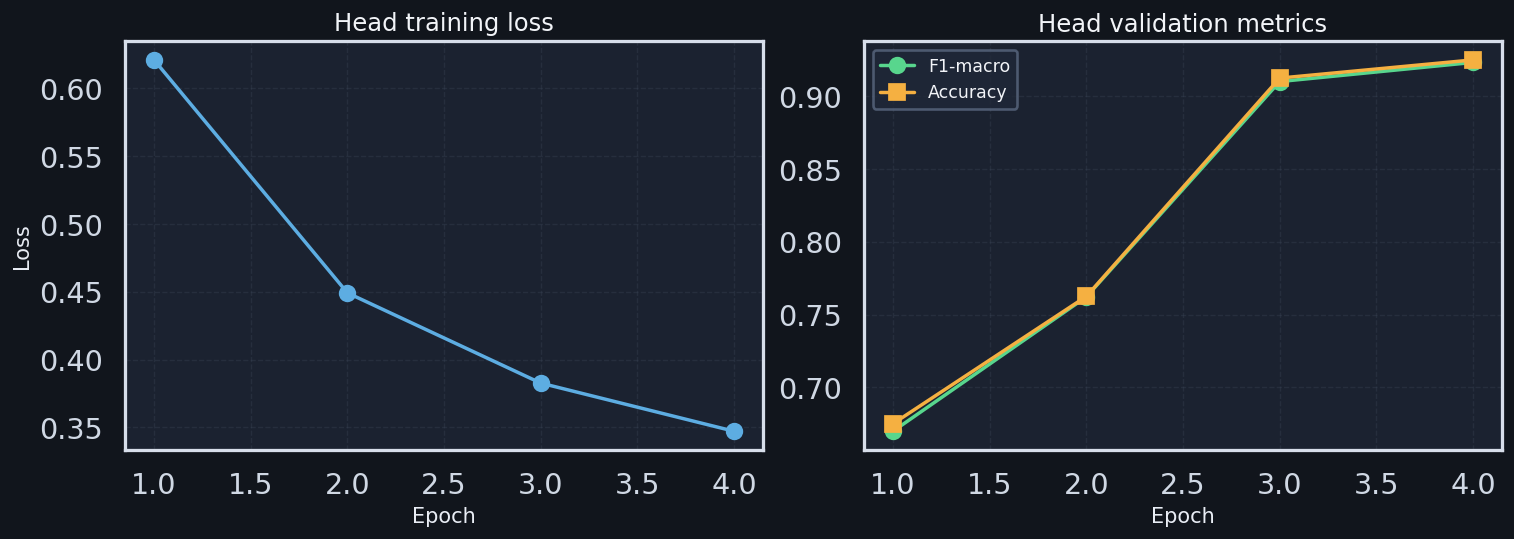

Frozen-extractor classifier quality:
{'accuracy': 0.925, 'f1_macro': 0.9232736572890026}
                      precision    recall  f1-score   support

  Accipiter striatus       0.90      0.98      0.93        44
Acropternis orthonyx       0.97      0.86      0.91        36

            accuracy                           0.93        80
           macro avg       0.93      0.92      0.92        80
        weighted avg       0.93      0.93      0.92        80

Анализ этапа head-only: метрики показывают, насколько хорошо решается задача без обновления extractor.


In [25]:
class AudioDataset(Dataset):
    def __init__(self, waves, labels):
        self.waves = waves
        self.labels = np.asarray(labels, dtype=np.int64)

    def __len__(self):
        return len(self.waves)

    def __getitem__(self, idx):
        return self.waves[idx], self.labels[idx]


def make_collate_fn(feat_extractor, sr):
    def _collate(batch):
        waves, labels = zip(*batch)
        encoded = feat_extractor(
            list(waves),
            sampling_rate=sr,
            return_tensors='pt',
            padding=True,
        )
        labels_t = torch.tensor(labels, dtype=torch.long)
        return encoded, labels_t

    return _collate


class Wav2VecClassifier(nn.Module):
    def __init__(self, backbone_name, num_classes, dropout=0.2):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(backbone_name)
        hidden = self.backbone.config.hidden_size
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden, num_classes),
        )

    def forward(self, input_values, attention_mask=None):
        out = self.backbone(input_values=input_values, attention_mask=attention_mask).last_hidden_state
        pooled = out.mean(dim=1)
        logits = self.classifier(pooled)
        return logits, out


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    losses = []

    for batch_inputs, batch_labels in loader:
        batch_inputs = {k: v.to(device) for k, v in batch_inputs.items()}
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()
        logits, _ = model(**batch_inputs)
        loss = criterion(logits, batch_labels)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    return float(np.mean(losses))


@torch.inference_mode()
def evaluate_model(model, loader):
    model.eval()
    all_true, all_pred = [], []

    for batch_inputs, batch_labels in loader:
        batch_inputs = {k: v.to(device) for k, v in batch_inputs.items()}
        logits, _ = model(**batch_inputs)
        pred = torch.argmax(logits, dim=1).cpu().numpy()
        all_pred.extend(pred.tolist())
        all_true.extend(batch_labels.numpy().tolist())

    acc = accuracy_score(all_true, all_pred)
    f1 = f1_score(all_true, all_pred, average='macro')
    return acc, f1, np.asarray(all_true), np.asarray(all_pred)


train_ds = AudioDataset(train_wavs_16k, y_train)
test_ds = AudioDataset(test_wavs_16k, y_test)
collate_fn = make_collate_fn(feature_extractor, BACKBONE_SR)

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, collate_fn=collate_fn)
test_loader = DataLoader(test_ds, batch_size=8, shuffle=False, collate_fn=collate_fn)

model = Wav2VecClassifier(BACKBONE_NAME, num_classes=len(class_names)).to(device)
criterion = nn.CrossEntropyLoss()

for p in model.backbone.parameters():
    p.requires_grad = False

optimizer_head = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)
EPOCHS_HEAD = 4

history_head = []
for epoch in range(1, EPOCHS_HEAD + 1):
    loss = train_one_epoch(model, train_loader, optimizer_head, criterion)
    acc, f1, _, _ = evaluate_model(model, test_loader)
    history_head.append({'epoch': epoch, 'train_loss': loss, 'test_acc': acc, 'test_f1_macro': f1})
    print(f'[Head] epoch={epoch} loss={loss:.4f} test_acc={acc:.4f} test_f1={f1:.4f}')

head_metrics_df = pd.DataFrame(history_head)
display(head_metrics_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
axes[0].plot(head_metrics_df['epoch'], head_metrics_df['train_loss'], marker='o', linewidth=2.0, color='#5DADE2')
axes[0].set_title('Head training loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[1].plot(head_metrics_df['epoch'], head_metrics_df['test_f1_macro'], marker='o', linewidth=2.0, color='#58D68D', label='F1-macro')
axes[1].plot(head_metrics_df['epoch'], head_metrics_df['test_acc'], marker='s', linewidth=2.0, color='#F5B041', label='Accuracy')
axes[1].set_title('Head validation metrics')
axes[1].set_xlabel('Epoch')
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.35, linestyle='--', linewidth=0.8)
plt.show()

acc_head, f1_head, y_true_head, y_pred_head = evaluate_model(model, test_loader)
print('Frozen-extractor classifier quality:')
print({'accuracy': acc_head, 'f1_macro': f1_head})
print(classification_report(y_true_head, y_pred_head, target_names=[str(x) for x in class_names]))
print('Анализ этапа head-only: метрики показывают, насколько хорошо решается задача без обновления extractor.')

# **7**. Fine-tuning extractor и классификационной головы

Теперь размораживаются параметры backbone, и модель дообучается целиком с меньшим learning rate. Gentle адаптируем внутренние представления под конкретные классы, не разрушая полезные предобученные паттерны.


$$
\theta \leftarrow \theta - \eta\,\nabla_\theta \mathcal{L}
$$

где при fine-tuning выбираем маленькое $\eta$.

Делаем всё тоже, что было выше.

[FineTune] epoch=1 loss=0.2875 test_acc=0.9125 test_f1=0.9093 best_f1=0.9093
[FineTune] epoch=2 loss=0.1366 test_acc=0.9625 test_f1=0.9618 best_f1=0.9618
[FineTune] epoch=3 loss=0.0828 test_acc=0.9500 test_f1=0.9495 best_f1=0.9618
[FineTune] epoch=4 loss=0.0743 test_acc=0.9625 test_f1=0.9622 best_f1=0.9622
[FineTune] epoch=5 loss=0.0188 test_acc=0.9875 test_f1=0.9873 best_f1=0.9873
[FineTune] epoch=6 loss=0.0314 test_acc=0.9500 test_f1=0.9497 best_f1=0.9873
[FineTune] epoch=7 loss=0.0195 test_acc=0.9625 test_f1=0.9618 best_f1=0.9873
Ранняя остановка: 2 эпохи без улучшения F1-macro.


,epoch,train_loss,test_acc,test_f1_macro
0,1,0.287485,0.9125,0.909312
1,2,0.136613,0.9625,0.961777
2,3,0.082821,0.9500,0.949495
3,4,0.074277,0.9625,0.962211
4,5,0.018787,0.9875,0.987340
5,6,0.031421,0.9500,0.949717
6,7,0.019491,0.9625,0.961777


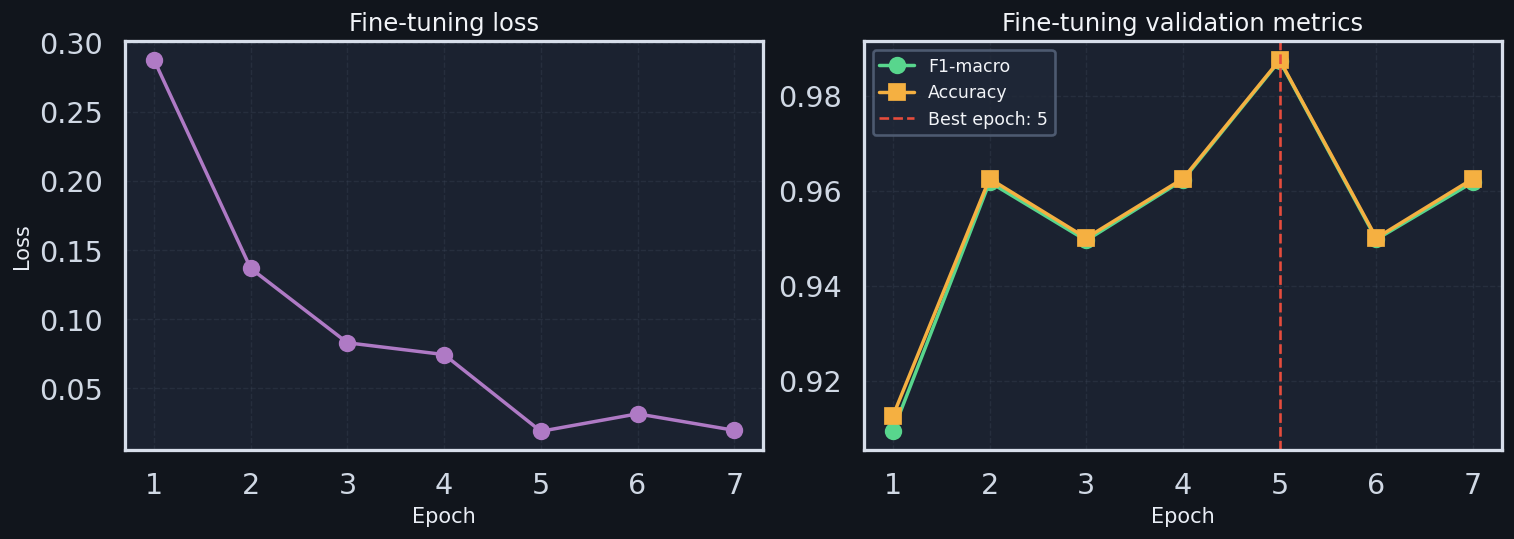

Fine-tuned classifier quality (best epoch restored):
{'best_epoch': 5, 'accuracy': 0.9875, 'f1_macro': 0.9873397689507833}
                      precision    recall  f1-score   support

  Accipiter striatus       0.98      1.00      0.99        44
Acropternis orthonyx       1.00      0.97      0.99        36

            accuracy                           0.99        80
           macro avg       0.99      0.99      0.99        80
        weighted avg       0.99      0.99      0.99        80



Fine-tuned features test: 100%|██████████| 10/10 [00:01<00:00,  7.69it/s]


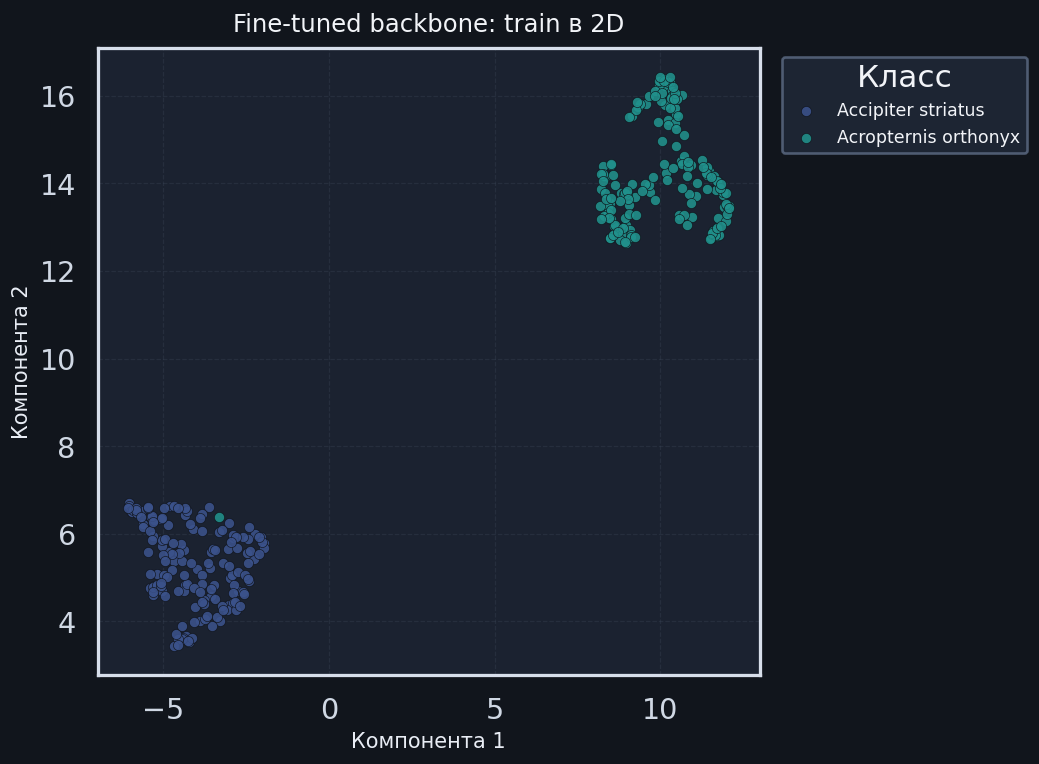

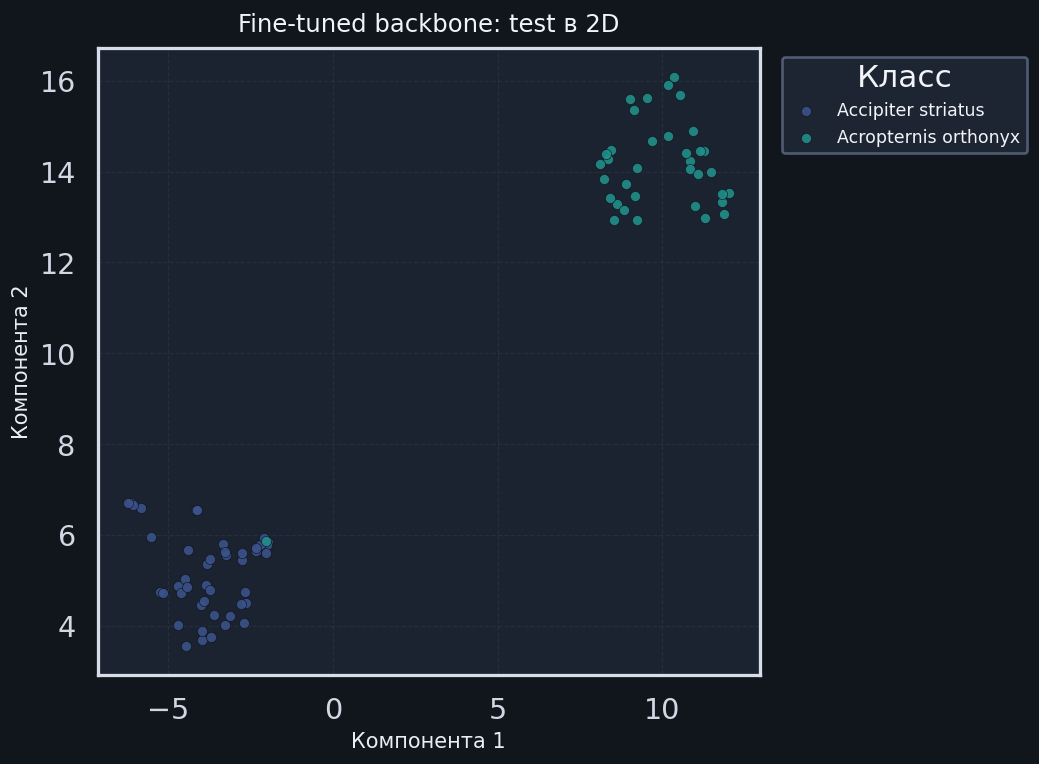

Fine-tuned-feature classical models:


,model,accuracy,f1_macro
0,LogReg,0.975,0.974747
1,SVM-RBF,0.975,0.974747
2,RandomForest,0.975,0.974747


Лучший алгоритм LogReg.
Качество: accuracy=0.9750, f1_macro=0.9747.


In [26]:
for p in model.backbone.parameters():
    p.requires_grad = True

optimizer_ft = torch.optim.AdamW(model.parameters(), lr=1e-5, weight_decay=0.01)
EPOCHS_FT = 8
PATIENCE_FT = 2

history_ft = []
best_f1_ft = float('-inf')
best_epoch_ft = 0
best_state_ft = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
epochs_without_improve = 0

for epoch in range(1, EPOCHS_FT + 1):
    loss = train_one_epoch(model, train_loader, optimizer_ft, criterion)
    acc, f1, _, _ = evaluate_model(model, test_loader)
    history_ft.append({'epoch': epoch, 'train_loss': loss, 'test_acc': acc, 'test_f1_macro': f1})

    if f1 > best_f1_ft:
        best_f1_ft = float(f1)
        best_epoch_ft = epoch
        best_state_ft = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        epochs_without_improve = 0
    else:
        epochs_without_improve += 1

    print(f'[FineTune] epoch={epoch} loss={loss:.4f} test_acc={acc:.4f} test_f1={f1:.4f} best_f1={best_f1_ft:.4f}')

    if epochs_without_improve >= PATIENCE_FT:
        print(f'Ранняя остановка: {PATIENCE_FT} эпохи без улучшения F1-macro.')
        break

model.load_state_dict(best_state_ft)
model.to(device)

ft_metrics_df = pd.DataFrame(history_ft)
display(ft_metrics_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
axes[0].plot(ft_metrics_df['epoch'], ft_metrics_df['train_loss'], marker='o', linewidth=2.0, color='#AF7AC5')
axes[0].set_title('Fine-tuning loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[1].plot(ft_metrics_df['epoch'], ft_metrics_df['test_f1_macro'], marker='o', linewidth=2.0, color='#58D68D', label='F1-macro')
axes[1].plot(ft_metrics_df['epoch'], ft_metrics_df['test_acc'], marker='s', linewidth=2.0, color='#F5B041', label='Accuracy')
axes[1].axvline(best_epoch_ft, color='#E74C3C', linestyle='--', linewidth=1.5, label=f'Best epoch: {best_epoch_ft}')
axes[1].set_title('Fine-tuning validation metrics')
axes[1].set_xlabel('Epoch')
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.35, linestyle='--', linewidth=0.8)
plt.show()

acc_ft, f1_ft, y_true_ft, y_pred_ft = evaluate_model(model, test_loader)
print('Fine-tuned classifier quality (best epoch restored):')
print({'best_epoch': best_epoch_ft, 'accuracy': acc_ft, 'f1_macro': f1_ft})
print(classification_report(y_true_ft, y_pred_ft, target_names=[str(x) for x in class_names]))


@torch.inference_mode()
def extract_finetuned_vectors(model, wave_list, batch_desc='Extracting fine-tuned features', batch_size=8):
    model.eval()
    vectors = []
    sequences = []

    for start in tqdm(range(0, len(wave_list), batch_size), desc=batch_desc):
        batch = wave_list[start:start + batch_size]
        encoded = feature_extractor(
            batch,
            sampling_rate=BACKBONE_SR,
            return_tensors='pt',
            padding=True,
        )
        encoded = {k: v.to(device) for k, v in encoded.items()}
        _, seq = model(**encoded)
        seq = seq.detach().cpu().numpy()

        if 'attention_mask' in encoded:
            lengths = encoded['attention_mask'].detach().cpu().numpy().sum(axis=1).astype(int)
        else:
            lengths = np.full(len(batch), seq.shape[1], dtype=int)

        for i, length in enumerate(lengths):
            valid_len = max(1, int(length))
            seq_i = seq[i, :valid_len]
            sequences.append(seq_i)
            vectors.append(np.concatenate([
                seq_i.mean(axis=0),
                seq_i.std(axis=0),
                seq_i.min(axis=0),
                seq_i.max(axis=0),
            ], axis=0))

    return np.asarray(vectors, dtype=np.float32), sequences


X_train_ft, train_seq_ft = extract_finetuned_vectors(model, train_wavs_16k, 'Fine-tuned features train')
X_test_ft, test_seq_ft = extract_finetuned_vectors(model, test_wavs_16k, 'Fine-tuned features test')

Xtr2_ft, Xte2_ft = reduce_to_2d(X_train_ft, X_test_ft, method='umap')
plot_2d_space(Xtr2_ft, y_train, class_names, 'Fine-tuned backbone: train в 2D')
plot_2d_space(Xte2_ft, y_test, class_names, 'Fine-tuned backbone: test в 2D')

ft_space_metrics, ft_space_models = evaluate_classic_models(X_train_ft, y_train, X_test_ft, y_test)
print('Fine-tuned-feature classical models:')
display(ft_space_metrics)
print_space_summary('fine-tuned признакового пространства', ft_space_metrics)


#  **8**. Лучшее пространство, пары объектов и спектрограммы

Лучшее --- максимальное значение macro-F1. Внутри этого пространства ищем две самые близкие и две самые дальние пары по евклидовой метрике

$$
\rho(i,j) = \lVert \mathbf{z}_i - \mathbf{z}_j \rVert_2
$$

Интерпретируем эти пары через спектрограммы. Используем Фурье

$$
S(\tau, \omega) = \sum_t x[t]w[t-\tau]e^{-j\omega t}
$$

интенсивность берём в dB-шкале:

$$
\mathrm{Spec}_{dB} = 20\log_{10}(|S| + \varepsilon)
$$

Если ближайшие пары чаще имеют одинаковые метки, пространство действительно группирует похожие аудио. Дальние пары, наоборот, помогают увидеть, какие спектральные структуры модель считает максимально различающимися.

Best feature space: FineTuned
Best F1-macro by space: {'MFCC': 0.9746031746031746, 'Pretrained': 0.9492063492063492, 'FineTuned': 0.9747474747474747}


,space,best_f1_macro
0,FineTuned,0.974747
1,MFCC,0.974603
2,Pretrained,0.949206


,kind,rank,distance,idx_i,idx_j,id_i,id_j,label_i,label_j
0,closest,1,10.047618,263,394,"20160517T0930_Acropternis_orthonyx_[1.0662,-76...","20160517T0930_Acropternis_orthonyx_[1.0662,-76...",Acropternis orthonyx,Acropternis orthonyx
1,closest,2,10.334533,142,149,"20160413T1430_Acropternis_orthonyx_[5.005,-75....","20160413T1430_Acropternis_orthonyx_[5.005,-75....",Acropternis orthonyx,Acropternis orthonyx
2,farthest,1,140.037857,159,391,"20090202T_Acropternis_orthonyx_[8.1565,-71.907...","20111018T0810_Accipiter_striatus_[39.8697,-75....",Acropternis orthonyx,Accipiter striatus
3,farthest,2,139.068176,76,159,"20121005T0800_Accipiter_striatus_[48.32,-123.5...","20090202T_Acropternis_orthonyx_[8.1565,-71.907...",Accipiter striatus,Acropternis orthonyx


Two closest pairs:


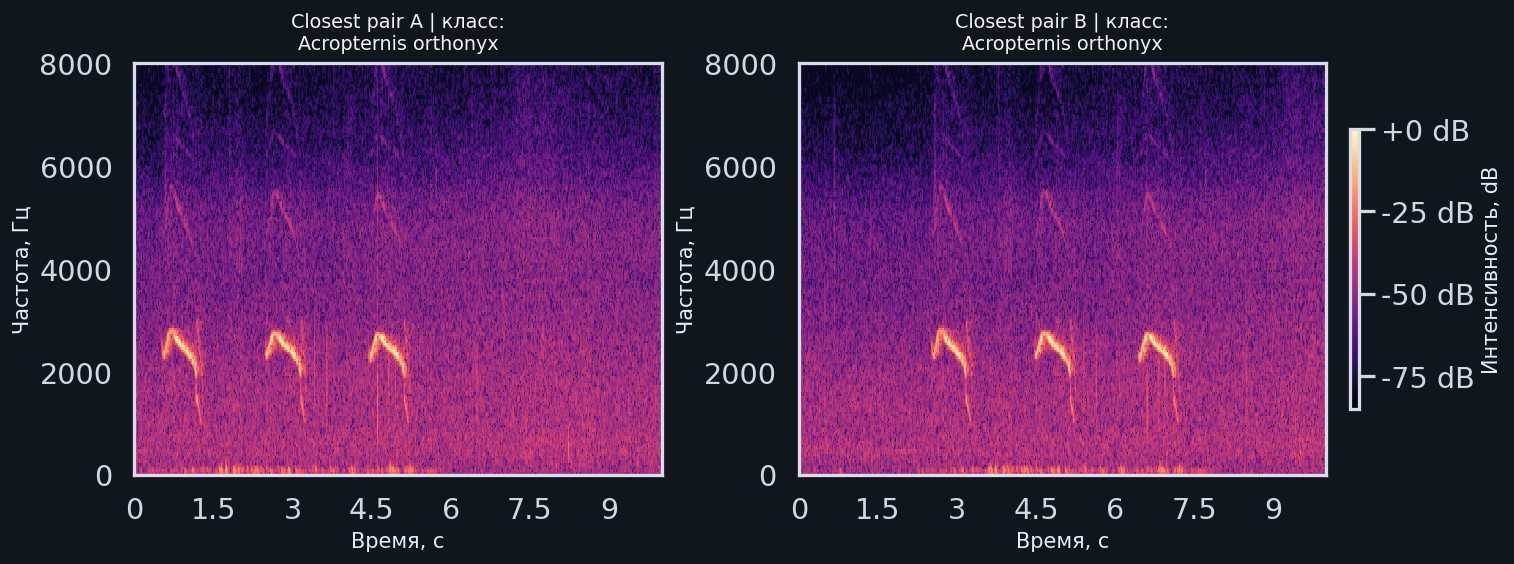

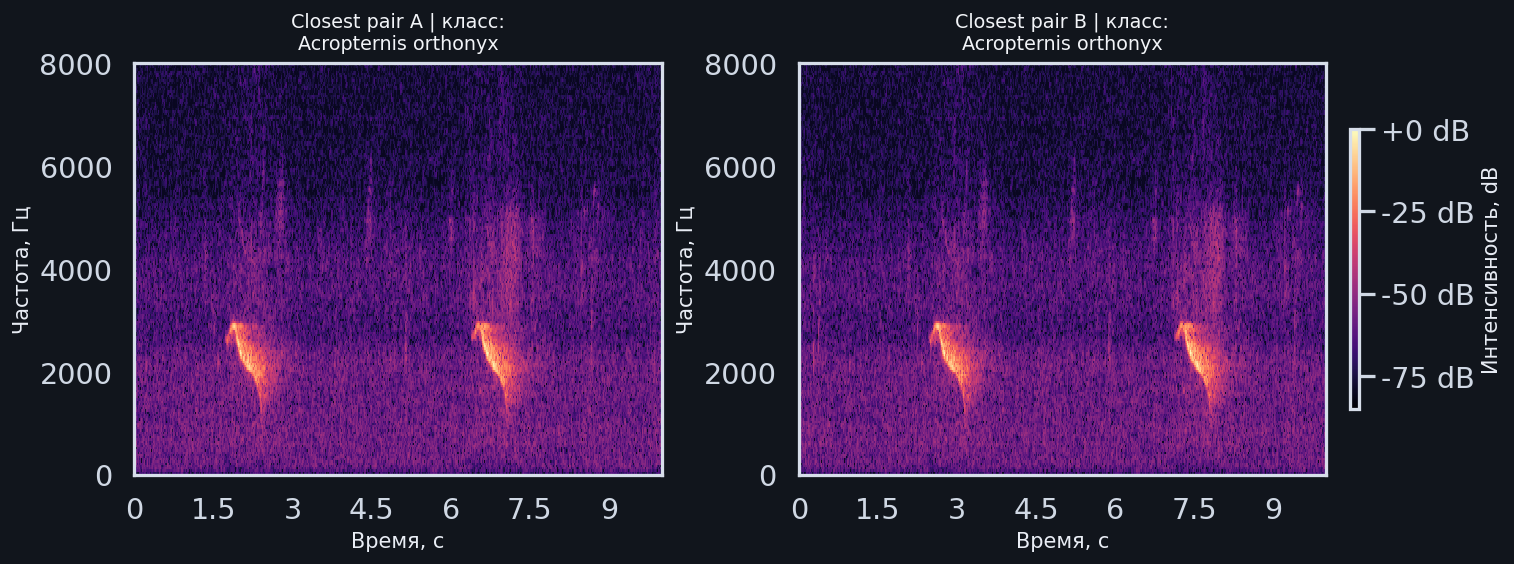

Two farthest pairs:


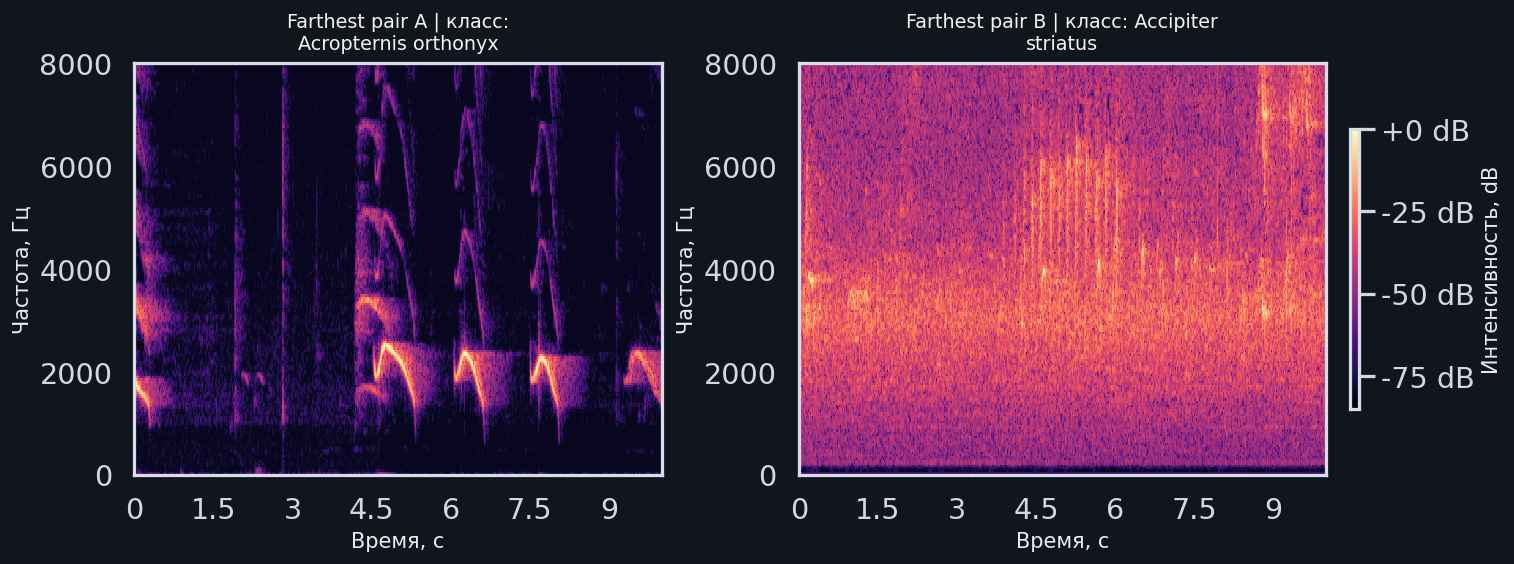

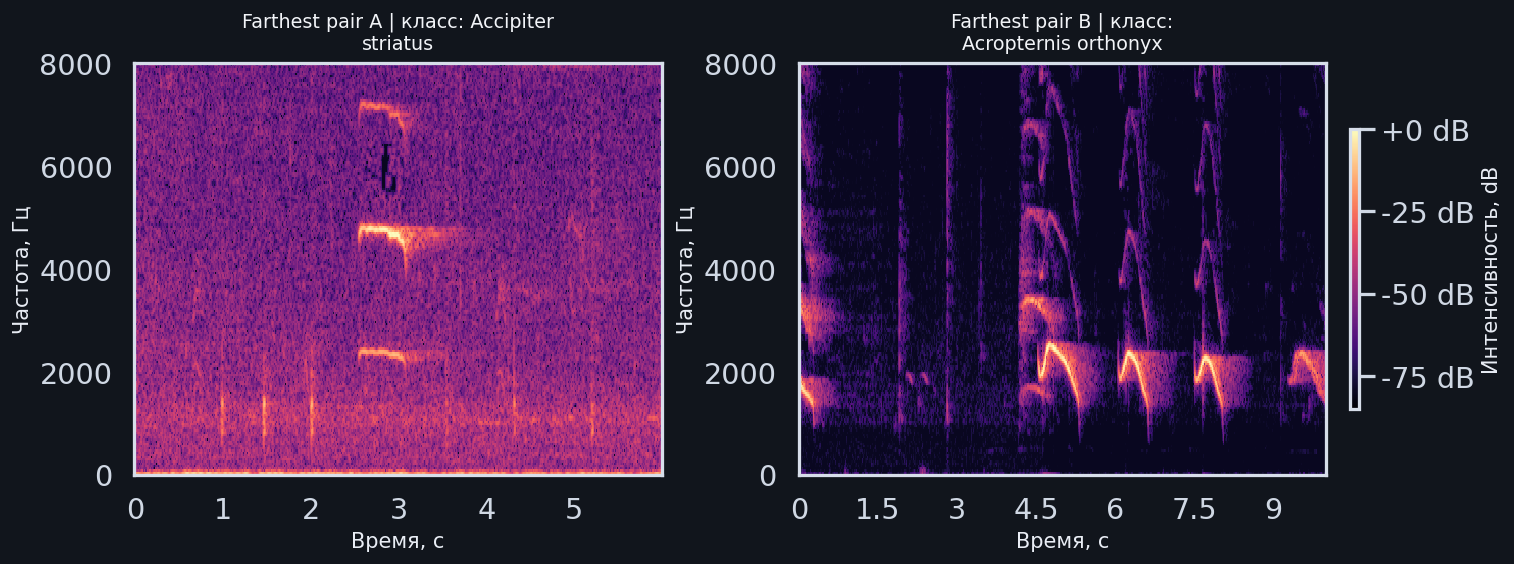

Для ближайших пар совпадение меток: 100.00%, для дальних пар: 0.00%.
Если ближайшие пары чаще одного класса, выбранное пространство хорошо группирует похожие аудио.


In [27]:
space_results = {
    'MFCC': mfcc_metrics,
    'Pretrained': pre_metrics,
    'FineTuned': ft_space_metrics,
}

space_best_f1 = {
    name: float(df['f1_macro'].max())
    for name, df in space_results.items()
}

best_space = max(space_best_f1, key=space_best_f1.get)
print('Best feature space:', best_space)
print('Best F1-macro by space:', space_best_f1)

display(
    pd.DataFrame({
        'space': list(space_best_f1.keys()),
        'best_f1_macro': list(space_best_f1.values()),
    }).sort_values('best_f1_macro', ascending=False).reset_index(drop=True)
)

if best_space == 'MFCC':
    X_best_train, X_best_test = X_train_mfcc, X_test_mfcc
elif best_space == 'Pretrained':
    X_best_train, X_best_test = X_train_pre, X_test_pre
else:
    X_best_train, X_best_test = X_train_ft, X_test_ft

all_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)
all_y = np.concatenate([y_train, y_test], axis=0)
X_best_all = np.vstack([X_best_train, X_best_test])

max_pairs_search = 2500
if len(X_best_all) > max_pairs_search:
    rng = np.random.RandomState(SEED)
    idx_sub = rng.choice(len(X_best_all), size=max_pairs_search, replace=False)
    X_for_pairs = X_best_all[idx_sub]
    df_for_pairs = all_df.iloc[idx_sub].reset_index(drop=True)
    y_for_pairs = all_y[idx_sub]
else:
    X_for_pairs = X_best_all
    df_for_pairs = all_df.reset_index(drop=True)
    y_for_pairs = all_y

X_for_pairs_sc = StandardScaler().fit_transform(X_for_pairs)
dist_vec = pdist(X_for_pairs_sc, metric='euclidean')

if len(dist_vec) < 2:
    raise ValueError('Недостаточно объектов для поиска двух ближайших и двух дальних пар.')


def condensed_index_to_pair(k, n):
    k = int(k)
    i = n - 2 - int(np.floor(np.sqrt(-8 * k + 4 * n * (n - 1) - 7) / 2.0 - 0.5))
    j = k + i + 1 - n * (n - 1) // 2 + (n - i) * (n - i - 1) // 2
    return int(i), int(j)


n_points = len(X_for_pairs_sc)
closest_idx = np.argpartition(dist_vec, 2)[:2]
closest_idx = closest_idx[np.argsort(dist_vec[closest_idx])]
farthest_idx = np.argpartition(dist_vec, -2)[-2:]
farthest_idx = farthest_idx[np.argsort(dist_vec[farthest_idx])[::-1]]

closest_pairs = [condensed_index_to_pair(idx, n_points) for idx in closest_idx]
farthest_pairs = [condensed_index_to_pair(idx, n_points) for idx in farthest_idx]

pairs_rows = []
for kind, pairs in [('closest', closest_pairs), ('farthest', farthest_pairs)]:
    for rank, (i, j) in enumerate(pairs, start=1):
        d = float(np.linalg.norm(X_for_pairs_sc[i] - X_for_pairs_sc[j]))
        pairs_rows.append({
            'kind': kind,
            'rank': rank,
            'distance': d,
            'idx_i': int(i),
            'idx_j': int(j),
            'id_i': str(df_for_pairs.loc[i, 'sample_id']),
            'id_j': str(df_for_pairs.loc[j, 'sample_id']),
            'label_i': class_names[int(y_for_pairs[i])],
            'label_j': class_names[int(y_for_pairs[j])],
        })

pairs_df = pd.DataFrame(pairs_rows)
display(pairs_df)


def plot_pair_spectrograms(df_local, pair, y_local, class_labels, title_prefix=''):
    i, j = pair
    y1 = df_local.loc[i, 'waveform']
    sr1 = int(df_local.loc[i, 'sr'])
    y2 = df_local.loc[j, 'waveform']
    sr2 = int(df_local.loc[j, 'sr'])

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)

    S1 = librosa.amplitude_to_db(np.abs(librosa.stft(y1, n_fft=1024, hop_length=256)) + 1e-8, ref=np.max)
    S2 = librosa.amplitude_to_db(np.abs(librosa.stft(y2, n_fft=1024, hop_length=256)) + 1e-8, ref=np.max)

    img1 = librosa.display.specshow(
        S1,
        sr=sr1,
        x_axis='time',
        y_axis='hz',
        ax=axes[0],
        cmap='magma',
        vmin=-85,
        vmax=0,
    )
    title_a = textwrap.fill(f'{title_prefix} A | класс: {class_labels[int(y_local[i])]}', width=34)
    axes[0].set_title(title_a, fontsize=11, pad=8)
    axes[0].set_ylim(0, min(sr1 / 2, 8000))
    axes[0].set_xlabel('Время, с')
    axes[0].set_ylabel('Частота, Гц')

    img2 = librosa.display.specshow(
        S2,
        sr=sr2,
        x_axis='time',
        y_axis='hz',
        ax=axes[1],
        cmap='magma',
        vmin=-85,
        vmax=0,
    )
    title_b = textwrap.fill(f'{title_prefix} B | класс: {class_labels[int(y_local[j])]}', width=34)
    axes[1].set_title(title_b, fontsize=11, pad=8)
    axes[1].set_ylim(0, min(sr2 / 2, 8000))
    axes[1].set_xlabel('Время, с')
    axes[1].set_ylabel('Частота, Гц')

    cbar = fig.colorbar(img2, ax=axes, format='%+2.0f dB', shrink=0.68, pad=0.02, aspect=30)
    cbar.set_label('Интенсивность, dB')

    plt.show()


print('Two closest pairs:')
for pair in closest_pairs:
    plot_pair_spectrograms(df_for_pairs, pair, y_for_pairs, class_names, title_prefix='Closest pair')

print('Two farthest pairs:')
for pair in farthest_pairs:
    plot_pair_spectrograms(df_for_pairs, pair, y_for_pairs, class_names, title_prefix='Farthest pair')

closest_same_ratio = np.mean(
    pairs_df[pairs_df['kind'] == 'closest']['label_i'] == pairs_df[pairs_df['kind'] == 'closest']['label_j']
)
farthest_same_ratio = np.mean(
    pairs_df[pairs_df['kind'] == 'farthest']['label_i'] == pairs_df[pairs_df['kind'] == 'farthest']['label_j']
)

print(
    f'Для ближайших пар совпадение меток: {closest_same_ratio:.2%}, '
    f'для дальних пар: {farthest_same_ratio:.2%}.'
)
print('Если ближайшие пары чаще одного класса, выбранное пространство хорошо группирует похожие аудио.')